# 02 · Numerical simulation methods: solvers, step sizes and model choices
**Level 1 · Foundations** &nbsp;|&nbsp; Course link: *Module 2 – Computational methods for energy networks*

AI models for energy are trained on data that very often comes from **simulators**. If the simulation is wrong or
too slow, the AI is wrong or impossible to train. This notebook shows, with measurements, how the choice of
**numerical method**, **step size**, **solver settings** and **network model** changes accuracy and speed.

1. **Dynamic simulation** (differential equations): grid frequency after a power-plant trip, solved with explicit
   Euler, Runge–Kutta and implicit methods; stability and *stiffness*.
2. **Steady-state simulation** (algebraic equations): power-flow algorithms (Newton–Raphson, fast-decoupled,
   Gauss–Seidel) and AC vs DC models on real benchmark grids.
3. **Coupling energy domains**: a heat-pump building (thermal model) co-simulated with the electricity grid.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from energy_ai import style
style()

## 1. Frequency dynamics after losing a power plant
The aggregated **swing equation** links the frequency deviation $\Delta f$ (p.u.) to the power imbalance; a
governor (turbine control) raises mechanical power $\Delta P_m$ with droop $R$ and time constant $T_g$:

$$2H\,\frac{d\Delta f}{dt} = \Delta P_m - \Delta P_L - D\,\Delta f,\qquad
  T_g\,\frac{d\Delta P_m}{dt} = -\Delta P_m - \frac{\Delta f}{R}$$

$H$ = inertia constant [s], $D$ = load damping, $\Delta P_L$ = lost generation (step). This is a linear ODE
$\dot x = Ax + b$; its eigenvalues tell how fast/oscillatory the response is.

In [2]:
H, D, R, Tg, dPL = 4.0, 1.0, 0.05, 0.5, 0.1          # 0.1 p.u. = 10 % of system load lost
f0 = 50.0

def rhs(t, x):
    df, dPm = x
    return [(dPm - dPL - D * df) / (2 * H), (-dPm - df / R) / Tg]

A = np.array([[-D / (2 * H), 1 / (2 * H)], [-1 / (R * Tg), -1 / Tg]])
print("eigenvalues of A:", np.round(np.linalg.eigvals(A), 3))

T_END = 20.0
ref = solve_ivp(rhs, (0, T_END), [0, 0], method="Radau", rtol=1e-10, atol=1e-12, dense_output=True)
t_ref = np.linspace(0, T_END, 2001)
f_ref = f0 * (1 + ref.sol(t_ref)[0])
print(f"frequency nadir: {f_ref.min():.3f} Hz at t = {t_ref[f_ref.argmin()]:.2f} s ; "
      f"steady state: {f_ref[-1]:.3f} Hz")

eigenvalues of A: [-1.062+2.03j -1.062-2.03j]


frequency nadir: 49.669 Hz at t = 0.99 s ; steady state: 49.762 Hz


### Fixed-step methods written by hand
* **Explicit (forward) Euler**: $x_{k+1} = x_k + h\,f(x_k)$ — first-order accurate, error $\propto h$.
* **Runge–Kutta 4 (RK4)**: four slope evaluations per step — fourth-order, error $\propto h^4$.
* **Implicit (backward) Euler**: $x_{k+1} = x_k + h\,f(x_{k+1})$ — solves an equation each step, but is
  **stable for any step size** on stable systems.

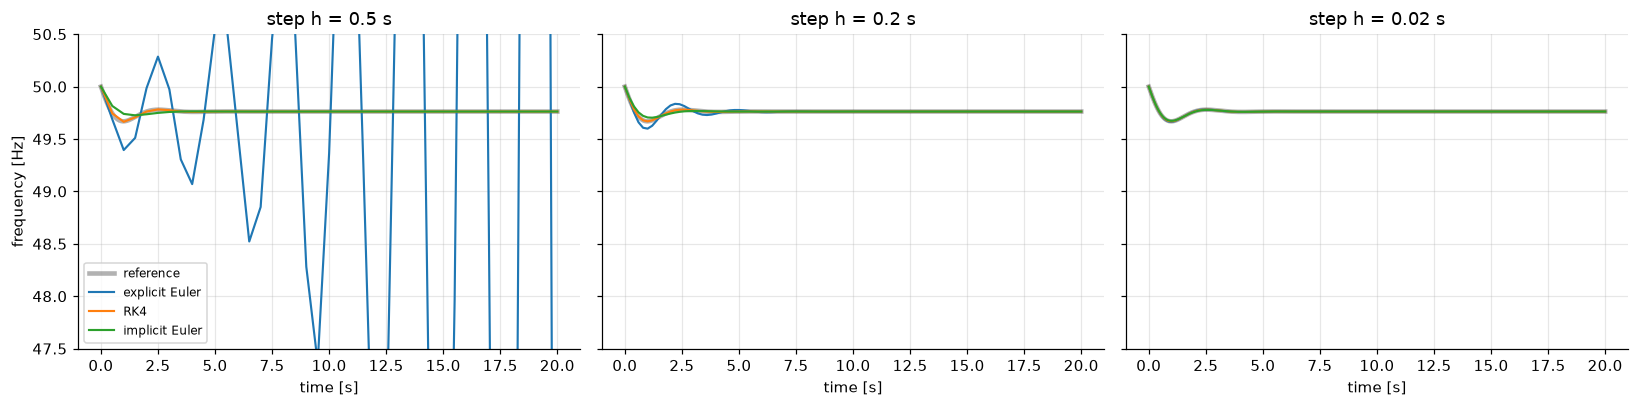

In [3]:
def euler(f, x0, h, T):
    t = np.arange(0, T + 1e-12, h); x = np.zeros((len(t), len(x0))); x[0] = x0
    for k in range(len(t) - 1):
        x[k + 1] = x[k] + h * np.asarray(f(t[k], x[k]))
    return t, x

def rk4(f, x0, h, T):
    t = np.arange(0, T + 1e-12, h); x = np.zeros((len(t), len(x0))); x[0] = x0
    for k in range(len(t) - 1):
        k1 = np.asarray(f(t[k], x[k])); k2 = np.asarray(f(t[k] + h / 2, x[k] + h / 2 * k1))
        k3 = np.asarray(f(t[k] + h / 2, x[k] + h / 2 * k2)); k4 = np.asarray(f(t[k] + h, x[k] + h * k3))
        x[k + 1] = x[k] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, x

def implicit_euler_linear(A, b, x0, h, T):     # x_{k+1} = (I - hA)^{-1} (x_k + h b)
    t = np.arange(0, T + 1e-12, h); x = np.zeros((len(t), len(x0))); x[0] = x0
    M = np.linalg.inv(np.eye(len(x0)) - h * A)
    for k in range(len(t) - 1):
        x[k + 1] = M @ (x[k] + h * b)
    return t, x

b_vec = np.array([-dPL / (2 * H), 0.0])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, h in zip(ax, (0.5, 0.2, 0.02)):
    a.plot(t_ref, f_ref, "k", lw=3, alpha=0.3, label="reference")
    for name, (t, x) in {"explicit Euler": euler(rhs, [0, 0], h, T_END), "RK4": rk4(rhs, [0, 0], h, T_END),
                         "implicit Euler": implicit_euler_linear(A, b_vec, np.zeros(2), h, T_END)}.items():
        a.plot(t, f0 * (1 + x[:, 0]), label=name, lw=1.4)
    a.set(title=f"step h = {h} s", xlabel="time [s]", ylim=(47.5, 50.5))
ax[0].set_ylabel("frequency [Hz]"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

With $h = 0.5$ s explicit Euler **oscillates and blows up** (numerical instability, not physics!). Implicit Euler
stays stable but is inaccurate (too smooth). RK4 is accurate already at moderate steps.

### Accuracy vs step size (convergence order)

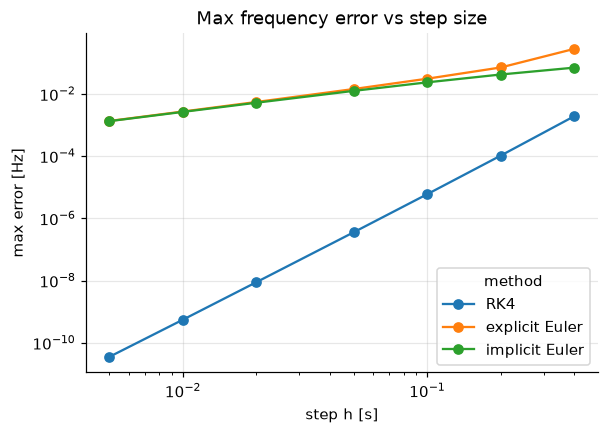

observed convergence order (slope): {'RK4': np.float64(4.13), 'explicit Euler': np.float64(1.41), 'implicit Euler': np.float64(0.83)}


In [4]:
hs = np.array([0.4, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005])
rows = []
for h in hs:
    for name, fn in (("explicit Euler", lambda h: euler(rhs, [0, 0], h, T_END)), ("RK4", lambda h: rk4(rhs, [0, 0], h, T_END)),
                     ("implicit Euler", lambda h: implicit_euler_linear(A, b_vec, np.zeros(2), h, T_END))):
        t, x = fn(h)
        err = np.max(np.abs(f0 * x[:, 0] - f0 * ref.sol(t)[0]))
        rows.append({"h": h, "method": name, "max error [Hz]": err})
err = pd.DataFrame(rows).pivot(index="h", columns="method", values="max error [Hz]")
ax = err.plot(loglog=True, marker="o", figsize=(6, 4), title="Max frequency error vs step size")
ax.set(xlabel="step h [s]", ylabel="max error [Hz]"); plt.show()
slopes = {m: np.polyfit(np.log(err.index[-4:]), np.log(err[m].values[-4:]), 1)[0] for m in err}
print("observed convergence order (slope):", {k: round(v, 2) for k, v in slopes.items()})

The measured slopes are close to theory: about 1 for the two Euler methods (first order; still slightly
pre-asymptotic here) and about 4 for RK4. Halving the step halves Euler's error but divides RK4's by 16.

### Stiff systems: why implicit solvers exist
Modern grids contain **power electronics** that react within milliseconds next to machines that react in seconds.
We add a fast frequency response (FFR) from batteries/converters with a 2 ms time constant. The system now has
time scales 1000× apart: it is **stiff**. Explicit methods must use tiny steps for *stability*, even when the
solution is smooth; implicit methods (BDF, Radau) can take large steps.

In [5]:
T_ffr, K_ffr = 0.002, 10.0

def rhs_stiff(t, x):
    df, dPm, p_ffr = x
    return [(dPm + p_ffr - dPL - D * df) / (2 * H), (-dPm - df / R) / Tg, (-p_ffr - K_ffr * df) / T_ffr]

rows = []
for method in ("RK45", "RK23", "DOP853", "LSODA", "BDF", "Radau"):
    t0 = time.perf_counter()
    sol = solve_ivp(rhs_stiff, (0, T_END), [0, 0, 0], method=method, rtol=1e-6, atol=1e-9)
    rows.append({"method": method, "implicit": method in ("BDF", "Radau", "LSODA"), "steps": len(sol.t) - 1,
                 "RHS evaluations": sol.nfev, "time [ms]": 1000 * (time.perf_counter() - t0),
                 "nadir [Hz]": f0 * (1 + sol.y[0].min())})
stiff = pd.DataFrame(rows).set_index("method")
display(stiff.round(3))
print("eigenvalues:", np.round(np.linalg.eigvals(np.array([[-D/(2*H), 1/(2*H), 1/(2*H)], [-1/(R*Tg), -1/Tg, 0], [-K_ffr/T_ffr, 0, -1/T_ffr]])), 1))

,implicit,steps,RHS evaluations,time [ms],nadir [Hz]
method,,,,,
RK45,False,3025,21140,218.885,49.79
RK23,False,4006,12029,164.181,49.79
DOP853,False,1566,18830,168.237,49.79
LSODA,True,196,404,3.334,49.79
BDF,True,169,342,25.858,49.79
Radau,True,102,719,27.274,49.79


eigenvalues: [-498.7+0.j    -1.7+2.2j   -1.7-2.2j]


All methods agree on the physics (same nadir, much better than before thanks to FFR), but the explicit
Runge–Kutta methods need **thousands of steps** while BDF/Radau need a few dozen. Rule: *stiff → implicit*.

## 2. Steady-state simulation: power-flow algorithms and network models
We solve the same SimBench grids (LV 15 buses, MV 97 buses, HV 306 buses) with different algorithms.

In [6]:
import pandapower as pp
import simbench as sb
import contextlib, io

def quiet_runpp(net, **kw):            # pandapower prints Iwamoto multipliers; keep the output clean
    with contextlib.redirect_stdout(io.StringIO()):
        pp.runpp(net, **kw)

rows = []
for code in ("1-LV-rural1--0-sw", "1-MV-rural--0-sw", "1-HV-mixed--0-sw"):
    net = sb.get_simbench_net(code)
    quiet_runpp(net)                                   # warm-up: the first call compiles code (numba)
    for alg, label in (("nr", "Newton–Raphson"), ("iwamoto_nr", "NR + Iwamoto damping"), ("fdbx", "Fast-decoupled (BX)"),
                       ("gs", "Gauss–Seidel")):
        try:
            quiet_runpp(net, algorithm=alg, max_iteration=20000 if alg == "gs" else "auto")   # warm-up per algorithm
            t0 = time.perf_counter()
            quiet_runpp(net, algorithm=alg, max_iteration=20000 if alg == "gs" else "auto")
            dt = time.perf_counter() - t0
            rows.append({"grid": code.split("--")[0], "buses": len(net.bus), "algorithm": label,
                         "iterations": net._ppc["iterations"], "time [ms]": 1000 * dt})
        except Exception as e:
            rows.append({"grid": code.split("--")[0], "buses": len(net.bus), "algorithm": label,
                         "iterations": np.nan, "time [ms]": np.nan, "note": type(e).__name__})
pf = pd.DataFrame(rows)
display(pf.pivot_table(index="algorithm", columns="grid", values="iterations").round(0))
display(pf.pivot_table(index="algorithm", columns="grid", values="time [ms]").round(1))

grid,1-HV-mixed,1-LV-rural1,1-MV-rural
algorithm,,,
Fast-decoupled (BX),15.0,11.0,16.0
Gauss–Seidel,3409.0,4695.0,10736.0
NR + Iwamoto damping,3.0,3.0,3.0
Newton–Raphson,3.0,3.0,3.0


grid,1-HV-mixed,1-LV-rural1,1-MV-rural
algorithm,,,
Fast-decoupled (BX),45.3,39.9,41.1
Gauss–Seidel,12799.3,4080.1,64981.9
NR + Iwamoto damping,42.9,40.8,39.8
Newton–Raphson,41.0,39.2,40.5


* **Newton–Raphson** converges in ~3 iterations on every grid (quadratic convergence) — the industry default.
* **Fast-decoupled** needs more but cheaper iterations (it reuses a constant Jacobian); good for high-voltage grids.
* **Gauss–Seidel** needs thousands of iterations and may fail: never use it for real grids.

### Network model: full AC vs linearised DC power flow
The DC power flow ignores losses, reactive power and voltage magnitudes ($P_{ij} \approx (\theta_i-\theta_j)/x_{ij}$).
It is linear (fast, convex — popular inside optimisation) but how wrong is it?

In [7]:
import networkx as nx
import pandapower.topology as top

rows = []
for code in ("1-HV-mixed--0-sw", "1-MV-rural--0-sw", "1-LV-rural1--0-sw"):
    net = sb.get_simbench_net(code)
    quiet_runpp(net); ac_p = net.res_line.p_from_mw.abs().copy(); ac_l = net.res_line.loading_percent.copy()
    v_range = net.res_bus.vm_pu.max() - net.res_bus.vm_pu.min()
    pp.rundcpp(net); dc_p = net.res_line.p_from_mw.abs().copy()
    ok = ac_l > 5                                       # lines that actually carry power
    rel = 100 * ((dc_p - ac_p).abs() / ac_p)[ok]
    loops = len(nx.cycle_basis(top.create_nxgraph(net, respect_switches=True, multi=False)))
    rows.append({"grid": code.split("--")[0], "loops in grid": loops,
                 "R/X (median)": (net.line.r_ohm_per_km / net.line.x_ohm_per_km).median(),
                 "flow error median [%]": rel.median(), "flow error max [%]": rel.max(),
                 "AC voltage spread [p.u.]": v_range, "DC gives voltages?": "no"})
display(pd.DataFrame(rows).set_index("grid").round(3))

,loops in grid,R/X (median),flow error median [%],flow error max [%],AC voltage spread [p.u.],DC gives voltages?
grid,,,,,,
1-HV-mixed,38,0.370,1.396,13.781,0.042,no
1-MV-rural,1,2.184,0.912,40.959,0.042,no
1-LV-rural1,0,2.570,0.156,3.395,0.007,no


Two different lessons:
* In a **radial** feeder (the LV grid has 0 loops) the active flows are dictated by the loads, so DC gets them almost right;
  but DC assumes all voltages are 1 p.u. and therefore **cannot see voltage problems**, which are the binding limit in
  long rural LV feeders (notebook 01). It also ignores reactive power and losses.
* In a **meshed** grid (HV: 38 loops) power splits over parallel paths according to impedances, and DC flow errors
  reach 10–14 %. The MV grid is almost radial (1 closed ring): small median error, but one line in the ring is off by ~40 %.

Model choice must match the question: AC for distribution grids and voltage studies; DC is acceptable for fast
screening of active flows in transmission grids (and is popular inside optimisation because it is linear).

## 3. Coupling energy domains: heat pump + building + grid (co-simulation)
Integrated energy systems couple **thermal** and **electrical** physics. We co-simulate:
* a building as a 1R1C thermal model $C\,\dot T_{in} = \frac{T_{out}-T_{in}}{R} + \dot Q_{hp}$,
* a heat pump with temperature-dependent efficiency $COP(T_{out}) \approx 0.08\,T_{out} + 3.3$, electric power $P = \dot Q_{hp}/COP$,
* the SimBench LV grid, where 6 households get such a heat pump.

At every 15-minute step the thermal simulator sends electric power to the grid simulator, which returns voltages:
this **exchange of variables between simulators** is the essence of co-simulation.

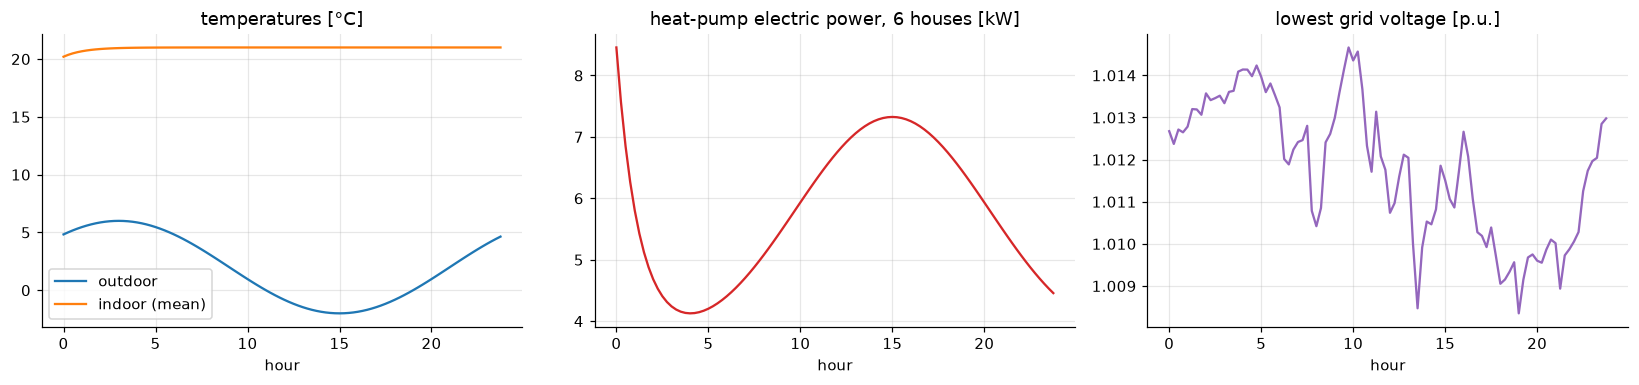

heat pumps add up to 8.5 kW; mean COP 3.46; lowest voltage 1.008 p.u.


In [8]:
from energy_ai import simbench_grid
net, prof = simbench_grid("1-LV-rural1--0-sw")
day = "2016-01-20"
steps = prof[("load", "p_mw")].loc[day].index
T_out = 2.0 - 4.0 * np.cos(2 * np.pi * (steps.hour + steps.minute / 60 - 15) / 24)   # cold day, warmest at 15:00
Rth, Cth, dt_s = 0.006, 1.2e7, 900.0             # K/W, J/K, 15-min step
hp_buses = net.load.index[:6]
T_in = np.full(len(hp_buses), 20.0)
log = []
for k, t in enumerate(steps):
    q_need = np.clip((21.0 - T_in) * 2500 + (21.0 - T_out[k]) / Rth, 0, 9000)   # simple P-controller, max 9 kW heat
    cop = 0.08 * T_out[k] + 3.3
    p_hp_mw = q_need / cop / 1e6
    T_in = T_in + dt_s / Cth * ((T_out[k] - T_in) / Rth + q_need)               # thermal step (explicit Euler)
    net.load["p_mw"] = prof[("load", "p_mw")].loc[t].values
    net.load.loc[hp_buses, "p_mw"] += p_hp_mw                                     # electrical coupling
    net.sgen["p_mw"] = prof[("sgen", "p_mw")].loc[t].values
    pp.runpp(net)
    log.append({"time": t, "T_out": T_out[k], "T_in_mean": T_in.mean(), "hp_kw": 1000 * p_hp_mw.sum(), "cop": cop,
                "v_min": net.res_bus.vm_pu.min(), "line_max": net.res_line.loading_percent.max()})
co = pd.DataFrame(log).set_index("time")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
h = co.index.hour + co.index.minute / 60
ax[0].plot(h, co.T_out, label="outdoor"); ax[0].plot(h, co.T_in_mean, label="indoor (mean)"); ax[0].set(title="temperatures [°C]"); ax[0].legend()
ax[1].plot(h, co.hp_kw, color="tab:red"); ax[1].set(title="heat-pump electric power, 6 houses [kW]")
ax[2].plot(h, co.v_min, color="tab:purple"); ax[2].set(title="lowest grid voltage [p.u.]")
for a in ax: a.set_xlabel("hour")
plt.tight_layout(); plt.show()
print(f"heat pumps add up to {co.hp_kw.max():.1f} kW; mean COP {co.cop.mean():.2f}; lowest voltage {co.v_min.min():.3f} p.u.")

Cold nights → low COP → high electric demand exactly when there is no PV: electrification of heat moves the grid
peak. Studying this requires **coupled** thermal–electrical simulation (in industry: co-simulation frameworks such
as mosaik or HELICS, or multi-domain tools such as OpenModelica; for pipe networks: `pandapipes`).

## Key takeaways
* Step size and method decide whether a dynamic simulation is accurate, unstable or merely slow.
* Stiff systems (power electronics + machines) need implicit solvers.
* Newton–Raphson is the power-flow default; the DC approximation fails in low-voltage grids.
* Integrated energy systems need coupled simulators exchanging variables every time step.

**Try it yourself:** lower the inertia `H` to 2 s (more renewables) and see the nadir; set `T_ffr = 0.0002` and
watch how many steps RK45 needs.